# Pontificia Universidad Javeriana
## Facultad de Ingeniería — Departamento de Bioingeniería
### Bioinformática (Periodo 2026-2)
### Segundo Parcial: Genómica Bacteriana, Anotación y Filogenia Molecular de Extremófilos

---

**Información del Examen:**
* **Fecha de Entrega:** Jueves 22 de octubre de 2026 (Tiempo de desarrollo: 1 semana)
* **Docente:** Juan Sebastián Malagón
* **Grupo:** 4
* **Integrantes:** 
  1. __________________________________________________
  2. __________________________________________________
  3. __________________________________________________

---

## Introducción y Contexto del Caso de Estudio

En el parcial anterior se confirmó, a partir de evidencias genómicas preliminares, la identidad del microorganismo extremófilo (piezófilo y psicrófilo) aislado de las aguas profundas y fosas abisales circundantes a la **Isla de Malpelo** (*Photobacterium profundum*). Una empresa biotecnológica aliada tiene un marcado interés comercial en la explotación de dos características fenotípicas clave de esta bacteria:
1. **Biosíntesis de ácidos grasos poliinsaturados de cadena larga (PUFA):** Principalmente ácido eicosapentaenoico (**EPA**, 20:5 $\omega$-3) y ácido docosahexaenoico (**DHA**, 22:6 $\omega$-3), lípidos esenciales de alto valor en las industrias nutracéutica, farmacéutica y de alimentos especializados por sus propiedades cardiovasculares, antiinflamatorias y neuroprotectoras.
2. **Enzimas piezotolerantes y psicrófilas:** Biocatalizadores adaptados a operar a presiones hidrostáticas extremas y bajas temperaturas sin desnaturalizarse, útiles en biocatálisis industrial en frío y procesamiento de alimentos sin degradación térmica.

<p align="center">
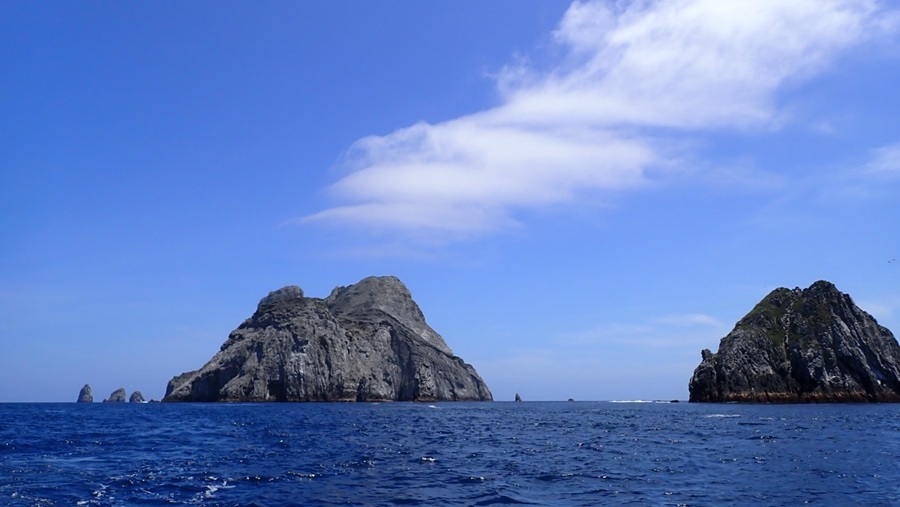
</p>
<p align="center"><em>Figura 1: Entorno abisal y aguas profundas del Santuario de Flora y Fauna Isla de Malpelo (Pacífico colombiano), nicho de aislamiento de Photobacterium profundum.</em></p>

### El Reto Biotecnológico
El cultivo a escala industrial de *Photobacterium profundum* en biorreactores abisales hiperbáricos representa un desafío tecnológico y económico significativo debido a los costos asociados al mantenimiento de presiones hiperbáricas elevadas. Por ello, la compañía aliada busca evaluar **alternativas industriales de microorganismos semejantes** pertenecientes al mismo linaje evolutivo que coexistan en ecosistemas marinos afines o de profundidad moderada, y que posean la maquinaria biosintética de PUFAs o enzimas adaptadas con eficiencias catalíticas iguales o superiores.

Para responder a esta necesidad, el centro de secuenciación ha entregado:
* Las lecturas crudas de secuenciación masiva (Illumina paired-end) de un nuevo aislado abisal promisorio.
* Una colección ambiental de secuencias homólogas de bacterias marinas y taxones de referencia para genómica comparativa.

---

### Fundamento del Marcador Filogenético: *gyrB* vs 16S ARNr

Para realizar la clasificación taxonómica y la reconstrucción filogenética de alta resolución de este aislado bacteriano, utilizaremos como marcador molecular el gen **_gyrB_**, el cual codifica para la **subunidad B de la ADN girasa bacteriana** (topoisomerase tipo II dependiente de ATP, clasificada con el término de Gene Ontology [GO:0003918](https://www.ebi.ac.uk/QuickGO/term/GO:0003918)).

**¿Por qué seleccionar *gyrB* en lugar del clásico 16S ARNr?**
1. **Poder de Resolución Taxonómica:** El gen 16S ARNr posee una tasa de evolución molecular lenta, lo cual es ventajoso para filogenias profundas (familias y órdenes), pero frecuentemente falla en discriminar especies crípticas o especies cercanamente emparentadas dentro de la familia *Vibrionaceae* y el género *Photobacterium* (donde dos especies distintas pueden compartir >99% de identidad en el 16S ARNr). En contraste, *gyrB* es un gen codificante de proteína sometido a selección purificadora pero con una tasa de sustitución sinónima significativamente mayor, proporcionando una variabilidad nucleotídica óptima para delinear especies y clados específicos.
2. **Copia Única en el Genoma:** A diferencia del operón ribosomal *rrn* (16S-23S-5S), que suele encontrarse en múltiples copias heterogéneas dentro de un mismo genoma bacteriano (generando artefactos en ensamblaje y alineamiento), *gyrB* es un gen esencial de copia única universalmente distribuido en bacterias, lo que garantiza una correspondencia ortóloga 1:1 en análisis comparativos.

---

> [!WARNING]
> ### RESTRICCIÓN OBLIGATORIA DE INFRAESTRUCTURA (2 HILOS)
> Debido a que compartimos los recursos de cómputo del servidor con todos los grupos del curso, **ES DE CARÁCTER ESTRICTAMENTE OBLIGATORIO configurar todas las herramientas y comandos a un máximo de 2 hilos de procesamiento** (`-t 2`, `--cpus 2` o `-threads 2`). 
> Cualquier proceso detectado con un número mayor de hilos será terminado por el sistema y acarreará penalizaciones académicas.

---

### Estructura de Datos del Proyecto
En el directorio de trabajo encontrarán la carpeta `./data/` con los archivos iniciales:
* `data/reads_R1.fastq`: Lecturas pareadas directas (Forward) de secuenciación Illumina.
* `data/reads_R2.fastq`: Lecturas pareadas inversas (Reverse) de secuenciación Illumina.
* `data/coleccion_gyrB.fasta`: Colección ambiental de secuencias homólogas del gen *gyrB* en formato FASTA.

Se recomienda estructurar las carpetas de salida organizadamente dentro de `./resultados/`:
* `./resultados/qc_inicial/`
* `./resultados/trimmomatic/`
* `./resultados/qc_final/`
* `./resultados/spades/`
* `./resultados/quast/`
* `./resultados/busco/`
* `./resultados/prokka/`
* `./resultados/eggnog/`
* `./resultados/comparativa/`
* `./resultados/filogenia/`


---
## Punto 1: Preprocesamiento y Control de Calidad de Lecturas NGS

### Contexto Bioinformático
Las tecnologías de secuenciación por síntesis (Illumina) producen lecturas pareadas (*paired-end*) en formato FASTQ, donde cada base nucleotídica viene acompañada de un puntaje de calidad **Phred ($Q$)**:
$$Q = -10 \log_{10}(P_{error})$$
Un puntaje $Q30$ equivale a una probabilidad de error de $1$ en $1000$ (precisión del $99.9\%$). No obstante, las reacciones de secuenciación suelen degradar su fidelidad hacia los extremos 3' de las lecturas debido al agotamiento de reactivos o pérdida de sincronía de los fluoróforos (*dephasing*), acumulando caídas de calidad y adaptadores de ligación residuales.

### Documentación Oficial de Herramientas
* **FastQC:** [https://www.bioinformatics.babraham.ac.uk/projects/fastqc/Help/](https://www.bioinformatics.babraham.ac.uk/projects/fastqc/Help/)
* **MultiQC:** [https://multiqc.info/docs/](https://multiqc.info/docs/)
* **Trimmomatic:** [http://www.usadellab.org/cms/?page=trimmomatic](http://www.usadellab.org/cms/?page=trimmomatic)

---

### 1.1 Diagnóstico Inicial con FastQC y MultiQC
**Instrucciones:**
1. Crea el directorio de salida `./resultados/qc_inicial/`.
2. Ejecuta `fastqc` sobre `data/reads_R1.fastq` y `data/reads_R2.fastq` empleando estrictamente **2 hilos** (`-t 2`).
3. Compila los reportes HTML generados utilizando `multiqc` para consolidar un único informe visual de calidad cruda.
4. Inspecciona los módulos de:
   * *Per base sequence quality* (perfil de calidad Phred a lo largo de los ciclos).
   * *Adapter Content* (presencia de adaptadores de secuenciación Illumina).
   * *Per base sequence content* y *Overrepresented sequences*.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 1.2 Depuración y Filtrado de Calidad con Trimmomatic
**Instrucciones:**
1. Crea el directorio `./resultados/trimmomatic/`.
2. Ejecuta `trimmomatic` en modo pareado (`PE`) con **máximo 2 hilos** (`-threads 2`).
3. Define los archivos de salida pareados (`clean_R1_paired.fastq`, `clean_R2_paired.fastq`) e impares/huérfanos (`clean_R1_unpaired.fastq`, `clean_R2_unpaired.fastq`).
4. Aplica los pasos de procesamiento:
   * `ILLUMINACLIP`: Detección y remoción de adaptadores Illumina (e.g. `TruSeq3-PE.fa:2:30:10`).
   * `SLIDINGWINDOW:4:20`: Ventana deslizante de 4 bases que recorta si la calidad promedio es menor a $Q20$.
   * `MINLEN:50`: Descarte de cualquier lectura cuya longitud final tras el corte sea inferior a 50 pares de bases.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 1.3 Control de Calidad Post-Trimming con FastQC y MultiQC
**Instrucciones:**
1. Crea el directorio `./resultados/qc_final/`.
2. Ejecuta `fastqc` con **2 hilos** (`-t 2`) sobre las lecturas limpias pareadas (`clean_R1_paired.fastq` y `clean_R2_paired.fastq`).
3. Ejecuta `multiqc` sobre la carpeta `./resultados/qc_final/` para generar el informe comparativo post-limpieza.
4. Compara el reporte inicial con el reporte final.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 2: Ensamblaje *De Novo* y Evaluación Genómica

### Contexto Bioinformático
El ensamblaje *de novo* reconstruye el genoma bacteriano a partir de millones de lecturas cortas solapadas sin requerir un genoma de referencia previo. El ensamblador **SPAdes** modela las lecturas mediante **grafos de De Bruijn** con múltiples tamaños de k-meros (*multi-k-mer graph*), lo que permite resolver regiones repetitivas y equilibrar la sensibilidad con la especificidad.

Una vez obtenido el ensamblaje en forma de *contigs*, es imperativo evaluar dos dimensiones complementarias:
1. **Contigüidad y Estructura con QUAST:** Evalúa qué tan fragmentado quedó el genoma mediante métricas estadísticas como el **N50** (la longitud del contig más pequeño tal que la suma de todos los contigs de igual o mayor tamaño abarca al menos el 50% de la longitud total del ensamblaje), el **L50**, el número total de contigs y el tamaño acumulado.
2. **Completitud y Redundancia Biológica con BUSCO:** Evalúa si los genes esenciales de copia única esperados para el linaje bacteriano (*bacteria_odb10*) fueron reconstruidos con éxito, clasificándolos en: Completos (C: Single [S] y Duplicated [D]), Fragmentados (F) y Desaparecidos (M).

### Documentación Oficial de Herramientas
* **SPAdes:** [https://cab.spbu.ru/software/spades/](https://cab.spbu.ru/software/spades/)
* **QUAST:** [https://quast.sourceforge.net/docs/manual.html](https://quast.sourceforge.net/docs/manual.html)
* **BUSCO:** [https://busco.ezlab.org/busco_userguide.html](https://busco.ezlab.org/busco_userguide.html)

---

### 2.1 Ensamblaje *De Novo* con SPAdes
**Instrucciones:**
1. Ejecuta `spades.py` utilizando las lecturas limpias pareadas (`clean_R1_paired.fastq` y `clean_R2_paired.fastq`).
2. Configura los parámetros obligatorios:
   * Modo aislamiento bacteriano: `--isolate`
   * Directorio de salida: `-o ./resultados/spades/`
   * Hilos de procesamiento: estrictamente 2 hilos (`-t 2`)
   * Límite de memoria RAM: `-m 3` (3 GB para proteger los recursos compartidos)
3. Al finalizar, verifica la existencia de `contigs.fasta` y `scaffolds.fasta` en la carpeta de resultados.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 2.2 Evaluación de Contigüidad con QUAST
**Instrucciones:**
1. Ejecuta `quast.py` sobre el archivo `./resultados/spades/contigs.fasta`.
2. Especifica el directorio de salida: `-o ./resultados/quast/`.
3. Limita la ejecución a 2 hilos: `-t 2`.
4. Visualiza e inspecciona el archivo `report.txt` o `report.html`.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 2.3 Evaluación de Completitud Biológica con BUSCO
**Instrucciones:**
1. Ejecuta `busco` sobre `./resultados/spades/contigs.fasta`.
2. Define los parámetros:
   * Modo de análisis: `-m genome`
   * Base de datos de linaje: `--lineage_dataset bacteria_odb10`
   * Directorio y nombre de salida: `-o busco_output --out_path ./resultados/`
   * Hilos de procesamiento: estrictamente 2 hilos (`--cpu 2`)
3. Muestra e interpreta el archivo de resumen corto (`short_summary.*.txt`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 3: Anotación Estructural, Funcional y Marcador *gyrB*

### Contexto Bioinformático
La anotación genómica se desarrolla en dos niveles jerárquicos:
1. **Anotación Estructural (Prokka):** Localiza las coordenadas físicas de las regiones codificantes de proteínas (**CDS**) mediante *Prodigal*, así como los genes de ARN de transferencia (**tRNA**) mediante *Aragorn* y ARN ribosomales (**rRNA**) mediante *Barrnap*. Genera archivos estándar de nucleótidos codificantes (`*.ffn`), aminoácidos traducidos (`*.faa`) y tablas de características (`*.tsv`, `*.gff`).
2. **Anotación Funcional Masiva (eggNOG-mapper):** Asigna funciones biológicas, dominios proteicos (Pfam), rutas metabólicas (KEGG) y términos ontológicos de **Gene Ontology (GO)** a través de grupos de ortología precomputados basados en alineamientos contra la base de datos *eggNOG*.

En esta fase, localizaremos el gen esencial **_gyrB_** empleando su ontología funcional **GO:0003918** (*DNA topoisomerase type II (ATP-hydrolyzing) activity*) y extraeremos su secuencia nucleotídica exacta mediante herramientas de manipulación de secuencias como `seqkit` o módulos de Python.

### Documentación Oficial de Herramientas
* **Prokka:** [https://manpages.debian.org/testing/prokka/prokka.1.en.html](https://manpages.debian.org/testing/prokka/prokka.1.en.html)
* **eggNOG-mapper:** [http://eggnog-mapper.embl.de/documentation.html](http://eggnog-mapper.embl.de/documentation.html)
* **SeqKit:** [https://bioinf.shenwei.me/seqkit/usage/](https://bioinf.shenwei.me/seqkit/usage/)

---

### 3.1 Anotación Estructural con Prokka
**Instrucciones:**
1. Ejecuta `prokka` sobre `./resultados/spades/contigs.fasta`.
2. Parámetros recomendados:
   * Directorio de salida: `--outdir ./resultados/prokka/`
   * Prefijo de archivos: `--prefix P_profundum`
   * Nombre del género y especie: `--genus Photobacterium --species profundum`
   * Hilos: estrictamente 2 (`--cpus 2`)
3. Inspecciona el archivo de resumen estadístico `P_profundum.txt` y los primeros registros de `P_profundum.tsv`.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 3.2 Anotación Funcional con eggNOG-mapper
**Instrucciones:**
1. Crea el directorio de salida `./resultados/eggnog/`.
2. Ejecuta `emapper.py` utilizando como entrada el archivo de proteínas generado por Prokka: `./resultados/prokka/P_profundum.faa`.
3. Parámetros requeridos:
   * Tipo de secuencia: `--itype proteins`
   * Modo: `-m diamond`
   * Directorio y prefijo de salida: `--output_dir ./resultados/eggnog/ -o P_profundum_annot`
   * Hilos de procesamiento: estrictamente 2 hilos (`--cpu 2`)
   * Parámetros de aceleración requeridos: `--dmnd_algo ctg --sensmode default --dmnd_iterate no`
4. Verifica la generación del archivo tabular `P_profundum_annot.emapper.annotations`.


In [ ]:
# 3.2 Anotación funcional con eggNOG-mapper (--cpu 2 --dmnd_algo ctg --sensmode default --dmnd_iterate no)
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 3.3 Búsqueda, Identificación y Extracción del Gen Marcador *gyrB*
**Instrucciones:**
1. Carga o filtra la tabla de anotaciones funcionales (`P_profundum_annot.emapper.annotations` o los archivos `P_profundum.tsv`/`P_profundum.gff`) para localizar el gen codificante de la **subunidad B de la ADN girasa**.
2. Verifica su asignación funcional por:
   * Nombre de gen: `gyrB`
   * Función ontológica: **GO:0003918**
   * Descripción de producto: *DNA gyrase subunit B* / *Type IIA topoisomerase*
3. Recupera con exactitud el **locus_tag** correspondiente (ej. `P_profundum_XXXXX`).
4. Utiliza `seqkit grep` o un script en Python (con `Bio.SeqIO`) para extraer la secuencia nucleotídica completa de *gyrB* a partir del archivo `./resultados/prokka/P_profundum.ffn` y guárdala en un archivo FASTA denominado `gyrB_aislado.fasta`.
5. Valida las propiedades biológicas de la secuencia extraída:
   * Longitud en pares de bases (debe ser aproximadamente ~2400 pb).
   * Codón de inicio canónico (ATG) y codón de parada (TAA, TAG o TGA).
   * Verificación de que la traducción no contenga codones de parada internos prematuros.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 4: Genómica Comparativa y Detección de Organismos Fuera de Distribución (OFDs) con PCoA

### Contexto Bioinformático
Para contextualizar evolutivamente nuestro aislado de *Photobacterium profundum* y explorar alternativas industriales para la producción de PUFA y enzimas piezotolerantes, debemos comparar su secuencia *gyrB* frente a la colección ambiental de secuencias homólogas proporcionada en `data/coleccion_gyrB.fasta`.

No obstante, en colecciones metagenómicas y ambientales es común que existan:
* Secuencias contaminantes o degradadas.
* Taxones anómalos pertenecientes a linajes filogenéticamente muy distantes (e.g. bacterias de otros filos como Firmicutes o Actinobacteria) o secuencias mal asignadas, denominados **Organismos Fuera de Distribución (OFDs - Out-of-Distribution Taxa)**.

La inclusión de OFDs en un alineamiento múltiple introduce ruido, inserciones masivas de gaps, alineamientos espurios y el artefacto filogenético de **atracción de ramas largas (*Long-Branch Attraction - LBA*)**, que distorsiona las relaciones evolutivas reales del grupo de interés (*Vibrionaceae*). 

Para detectarlos de manera no supervisada:
1. Alineamos la colección completa junto a nuestro aislado usando **MUSCLE**.
2. Calculamos la matriz de **distancia de Hamming** (proporción de diferencias por sitio alineado).
3. Aplicamos un **Análisis de Coordenadas Principales (PCoA / MDS clásico)** con `sklearn.manifold.MDS`.
4. Graficamos el espacio de dispersión (PC1 vs PC2) con `matplotlib` para identificar los puntos atípicos (OFDs) y removerlos antes de la inferencia filogenética.

### Documentación Oficial de Herramientas
* **MUSCLE:** [https://drive5.com/muscle/manual/](https://drive5.com/muscle/manual/)
* **SciPy Spatial Distance:** [https://docs.scipy.org/doc/scipy/reference/spatial.distance.html](https://docs.scipy.org/doc/scipy/reference/spatial.distance.html)
* **scikit-learn MDS / PCoA:** [https://scikit-learn.org/stable/modules/generated/sklearn.manifold.MDS.html](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.MDS.html)
* **Matplotlib Scatter:** [https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)

---

### 4.1 Integración de Secuencias y Alineamiento Múltiple con MUSCLE
**Instrucciones:**
1. Concatena la secuencia extraída de tu aislado (`gyrB_aislado.fasta`) con la colección ambiental (`data/coleccion_gyrB.fasta`) para conformar un único archivo multifasta: `./resultados/comparativa/coleccion_total_gyrB.fasta`.
2. Asegúrate de que el encabezado del aislado esté claramente identificado (ej. `>Photobacterium_profundum_Malpelo`).
3. Ejecuta **MUSCLE** sobre la colección total para producir el alineamiento múltiple de secuencias: `./resultados/comparativa/gyrB_alineado.fasta`.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.2 Matriz de Distancias de Hamming y Proyección PCoA (MDS)
**Instrucciones:**
1. Carga el alineamiento múltiple (`gyrB_alineado.fasta`) usando `Bio.AlignIO` de BioPython.
2. Calcula la matriz de distancias de Hamming normalizada ($N \times N$) entre todos los pares de secuencias:
   $$D_{\text{Hamming}}(s_i, s_j) = \frac{1}{L} \sum_{k=1}^L \mathbb{I}(s_{ik} \neq s_{jk})$$
   *(puedes apoyarte en `scipy.spatial.distance.pdist` con métrica `'hamming'` o calcularla directamente en NumPy)*.
3. Aplica **Escalamiento Multidimensional (MDS)** con `sklearn.manifold.MDS` configurando:
   * `n_components=2`
   * `dissimilarity='precomputed'`
   * `random_state=42`
4. Extrae las dos primeras coordenadas principales (PC1 y PC2).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.3 Visualización del PCoA y Detección de OFDs
**Instrucciones:**
1. Genera un gráfico de dispersión bidimensional (PC1 vs PC2) utilizando `matplotlib.pyplot.scatter`.
2. Etiqueta cada punto con el nombre del organismo o taxón correspondiente.
3. Resalta con un color y marcador distintivo (e.g. estrella dorada o roja) la posición de tu aislado problema (`Photobacterium_profundum_Malpelo`).
4. Identifica visualmente qué taxones se proyectan como valores atípicos extremos (**OFDs**), apartados del cúmulo principal de bacterias marinas.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.4 Depuración del Alineamiento (Remoción de OFDs)
**Instrucciones:**
1. Filtra y remueve los taxones identificados como OFDs tanto del archivo FASTA original como del alineamiento.
2. Genera el nuevo archivo de alineamiento limpio y depurado: `./resultados/comparativa/gyrB_depurado_alineado.fasta`.
3. Confirma que en la colección depurada permanezcan únicamente las especies marinas relevantes (miembros del orden *Vibrionales* y afines) junto a tu aislado de *Photobacterium profundum*.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 5: Señales Evolutivas y Reconstrucción Filogenética

### Contexto Bioinformático
Una vez depurado el alineamiento, procederemos a la inferencia de la filogenia molecular. Para estimar la verdadera distancia evolutiva entre secuencias homólogas no basta la distancia observada $p$ (Hamming), debido a que a lo largo de millones de años ocurren **sustituciones múltiples superpuestas en el mismo sitio** (*múltiples hits* o saturación mutacional).

Para corregir este fenómeno emplearemos el modelo probabilístico de **Jukes-Cantor (JC69)**:
$$d_{\text{JC}} = -\frac{3}{4} \ln\left(1 - \frac{4}{3} p\right)$$
donde $p$ es la proporción de nucleótidos no idénticos observados entre dos secuencias.

A partir de la matriz de distancias corregidas, utilizaremos el algoritmo de **Neighbor-Joining (NJ)** (Saitou & Nei, 1987). Neighbor-Joining es un método de agrupamiento jerárquico que no asume una tasa constante de evolución molecular , lo que permite modelar ramas con diferentes velocidades de divergencia evolutiva.

### Documentación Oficial de Herramientas
* **BioPython Phylo Wiki:** [https://biopython.org/wiki/Phylo](https://biopython.org/wiki/Phylo)
* **Bio.Phylo.TreeConstruction API:** [https://biopython.org/docs/latest/api/Bio.Phylo.TreeConstruction.html](https://biopython.org/docs/latest/api/Bio.Phylo.TreeConstruction.html)
* **Tutorial Oficial de BioPython (Capítulo Filogenia):** [https://biopython.org/DIST/docs/tutorial/Tutorial.html#sec379](https://biopython.org/DIST/docs/tutorial/Tutorial.html#sec379)

---

### 5.1 Cálculo de la Matriz de Distancias bajo el Modelo Jukes-Cantor (JC69)
**Instrucciones:**
1. Carga el alineamiento limpio (`gyrB_depurado_alineado.fasta`) usando `Bio.AlignIO`.
2. Calcula la matriz de distancias evolutivas corrigiendo las distancias observadas bajo la fórmula de **Jukes-Cantor**. Puedes utilizar:
   * La clase `DistanceCalculator` de `Bio.Phylo.TreeConstruction` con el modelo correspondiente (o calculando la matriz corregida mediante la fórmula analítica de JC69).
3. Inspecciona las distancias genéticas entre tu aislado y las demás especies del género *Photobacterium*.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 5.2 Reconstrucción del Árbol Filogenético por Neighbor-Joining (NJ)
**Instrucciones:**
1. Instancia el constructor de árboles: `constructor = DistanceTreeConstructor()`.
2. Aplica el algoritmo de agrupamiento Neighbor-Joining pasándole la matriz de distancias calculada: `arbol = constructor.nj(dist_matrix)`.
3. Guarda el árbol resultante en formato Newick (`.nwk`) o PhyloXML en `./resultados/filogenia/arbol_gyrB_NJ.nwk`.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 5.3 Visualización del Árbol Filogenético y Taxones Hermanos
**Instrucciones:**
1. Visualiza y grafica el árbol filogenético empleando `Bio.Phylo.draw` o renderizándolo con `matplotlib`.
2. Ajusta el tamaño de la figura, tipografía y resolución para que todos los nombres de los taxones y las longitudes de rama sean legibles.
3. Resalta la rama y posición correspondiente a tu aislado de *Photobacterium profundum* de Malpelo.
4. Identifica con precisión cuáles son los **taxones hermanos (*sister taxa*)** inmediatos que forman clado monofilético con tu aislado.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)
